# 00 · Extracción de frames de los vídeos

**Objetivo:** extraer fotogramas a intervalos regulares de los vídeos seleccionados del dataset DFL Bundesliga Data Shootout, generando la base de imágenes que se etiquetarán posteriormente para entrenar el modelo de detección de jugadores, árbitros y balón.

**Contexto:** los modelos de visión por computador se entrenan con imágenes estáticas, no con vídeos. Por tanto, antes de poder etiquetar cualquier cosa es necesario convertir los vídeos en frames individuales. La elección del intervalo entre frames es importante: intervalos muy cortos generan imágenes casi idénticas que aportan poca información adicional, mientras que intervalos muy largos pierden representatividad de las situaciones de juego.

**Entrada:** vídeos `.mp4` ubicados en `data/raw/`.

**Salida:** imágenes `.jpg` organizadas en subcarpetas por vídeo dentro de `data/frames/`.

## 1. Configuración

Se definen las rutas del proyecto y el intervalo de extracción.

In [1]:
import cv2
import os
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
VIDEOS_DIR = REPO_ROOT / "data" / "raw"
FRAMES_DIR = REPO_ROOT / "data" / "frames"
FRAME_INTERVAL = 0.5

print(f"Directorio de vídeos: {VIDEOS_DIR}")
print(f"Directorio de frames: {FRAMES_DIR}")
print(f"Intervalo entre frames: {FRAME_INTERVAL} segundos")

Directorio de vídeos: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\raw
Directorio de frames: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\frames
Intervalo entre frames: 0.5 segundos


## 2. Justificación del intervalo de extracción

Con vídeos a 25 fps y un intervalo de 0.5 segundos entre frames extraídos, se obtiene aproximadamente 1 frame de cada 13 originales. Esto supone unos 63 frames por vídeo de 30 segundos, equilibrio razonable entre volumen y representatividad. Intervalos menores generarían frames consecutivos muy similares que aportarían poco valor al entrenamiento del modelo.

## 3. Inventario de vídeos disponibles

Antes de procesar, se listan los vídeos presentes en la carpeta de entrada para verificar que están todos los esperados.

In [2]:
videos = sorted([f for f in os.listdir(VIDEOS_DIR) if f.endswith(".mp4")])

print(f"Vídeos encontrados: {len(videos)}\n")
for v in videos:
    path = VIDEOS_DIR / v
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"  {v} ({size_mb:.1f} MB)")

Vídeos encontrados: 12

  A1606b0e6_0 (12).mp4 (23.5 MB)
  A1606b0e6_0 (21).mp4 (25.4 MB)
  A1606b0e6_0 (26).mp4 (22.4 MB)
  A1606b0e6_0 (37).mp4 (23.0 MB)
  A1606b0e6_0 (62).mp4 (22.5 MB)
  A1606b0e6_0 (7).mp4 (22.8 MB)
  A1606b0e6_0 (9).mp4 (20.1 MB)
  C35bd9041_0 (14).mp4 (33.2 MB)
  C35bd9041_0 (18).mp4 (23.0 MB)
  E3c993bd2_0 (13).mp4 (24.5 MB)
  test (10).mp4 (28.4 MB)
  test (27).mp4 (20.4 MB)


## 4. Función de extracción

La función recorre cada vídeo frame a frame y guarda solo aquellos que coinciden con el intervalo configurado. El cálculo del paso se hace en función del fps real del vídeo, lo que permite que el sistema funcione correctamente independientemente del frame rate de cada clip.

In [3]:
def extract_frames(video_path: Path, output_dir: Path, interval: float) -> int:
    video_name = video_path.stem
    video_output_dir = output_dir / video_name
    video_output_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_step = int(fps * interval)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"Procesando: {video_name} | FPS: {fps:.1f} | Frames totales: {total_frames}")

    frame_idx = 0
    saved = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % frame_step == 0:
            filename = f"{video_name}_frame{frame_idx:05d}.jpg"
            cv2.imwrite(str(video_output_dir / filename), frame)
            saved += 1
        frame_idx += 1

    cap.release()
    print(f"  → {saved} frames guardados\n")
    return saved

## 5. Ejecución sobre todos los vídeos

In [4]:
total = 0
resultados = {}

for video_file in videos:
    video_path = VIDEOS_DIR / video_file
    saved = extract_frames(video_path, FRAMES_DIR, FRAME_INTERVAL)
    resultados[video_file] = saved
    total += saved

print("="*50)
print(f"Total frames extraídos: {total}")
print(f"Promedio por vídeo: {total / len(videos):.1f}")

Procesando: A1606b0e6_0 (12) | FPS: 25.0 | Frames totales: 749
  → 63 frames guardados

Procesando: A1606b0e6_0 (21) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: A1606b0e6_0 (26) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: A1606b0e6_0 (37) | FPS: 25.0 | Frames totales: 749
  → 63 frames guardados

Procesando: A1606b0e6_0 (62) | FPS: 25.0 | Frames totales: 749
  → 63 frames guardados

Procesando: A1606b0e6_0 (7) | FPS: 25.0 | Frames totales: 749
  → 63 frames guardados

Procesando: A1606b0e6_0 (9) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: C35bd9041_0 (14) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: C35bd9041_0 (18) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: E3c993bd2_0 (13) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: test (10) | FPS: 25.0 | Frames totales: 750
  → 63 frames guardados

Procesando: test (27) | FPS: 25.0 | Frame

## 6. Resumen visual de los frames extraídos

Para verificar que la extracción ha funcionado correctamente, se visualizan algunos frames de muestra.

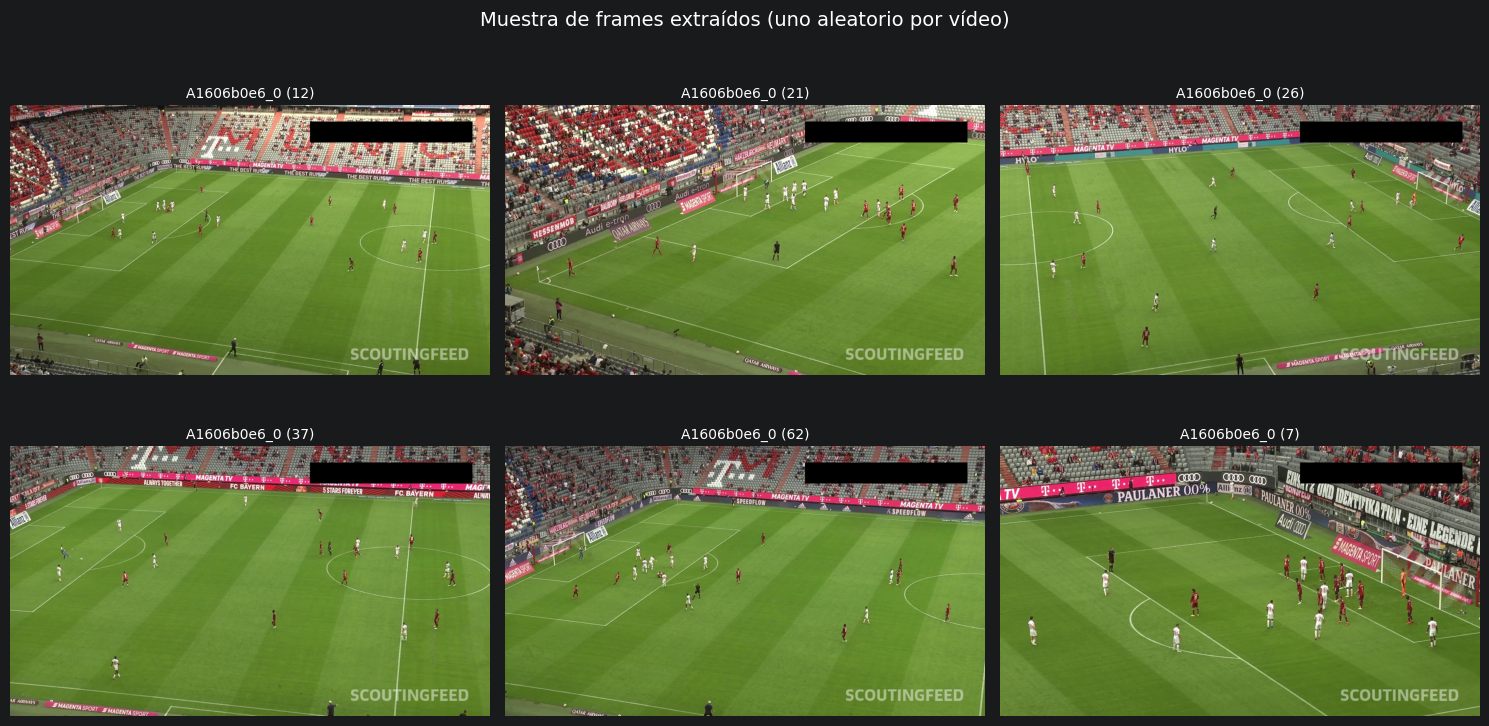

In [5]:
import matplotlib.pyplot as plt
import random

subdirs = [d for d in FRAMES_DIR.iterdir() if d.is_dir()]
muestras = []

for subdir in subdirs[:6]:
    frames_en_subdir = list(subdir.glob("*.jpg"))
    if frames_en_subdir:
        muestras.append(random.choice(frames_en_subdir))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, frame_path in zip(axes.flat, muestras):
    img = cv2.imread(str(frame_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(frame_path.parent.name, fontsize=10)
    ax.axis("off")

plt.suptitle("Muestra de frames extraídos (uno aleatorio por vídeo)", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Conclusiones

Tras la ejecución de este notebook:

- Se han extraído frames de todos los vídeos disponibles a intervalos regulares de 0.5 segundos.
- Los frames quedan organizados por subcarpetas según el vídeo de origen, lo que facilita el seguimiento posterior.
- El volumen obtenido es manejable para etiquetado manual y suficiente para entrenar un primer modelo.

Estos frames constituyen la materia prima para el siguiente notebook, donde se realizará el etiquetado inicial y el entrenamiento del primer modelo de detección.